In this noteboook, we will be perturbing the top 3 PCs of the Birds image embeddings and reconstructing perturbed images via StableDiffusion in an endeavor to interpret those 3 principal dimensions and what they encode. We also create a synthetic 'prototypical bird' in CLIP embedding space using the mean embedding, and perturb that along principal axes to gain an overall understanding of the changes induced in each latent dimension.

Pipeline designed by Nandini

In [ ]:
!pip install --upgrade diffusers[torch]
!pip install diffusers
!pip install transformers
!pip install torch

In [1]:
import os
from pathlib import Path

In [2]:
import requests
import torch
from PIL import Image
import matplotlib.pyplot as plt
from io import BytesIO
import numpy as np
from tqdm import tqdm
import pandas as pd
import numpy as np
import os
from sklearn.decomposition import PCA
import matplotlib.gridspec as gridspec

In [3]:
from diffusers import StableUnCLIPImg2ImgPipeline
from transformers import CLIPTextModelWithProjection, CLIPTokenizer

2025-12-07 17:16:16.069917: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2025-12-07 17:16:16.069977: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2025-12-07 17:16:16.071329: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-12-07 17:16:16.079217: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [4]:
# Loading pre-generated CLIP embeddings from THINGS Birds
birds_emb = np.load('birds_emb.npy')

In [5]:
# We first visualize what each of the original embeddings look like in the PC space where n_components =3
pca_birds = PCA(n_components=3)
birds_pca = pca_birds.fit_transform(birds_emb)

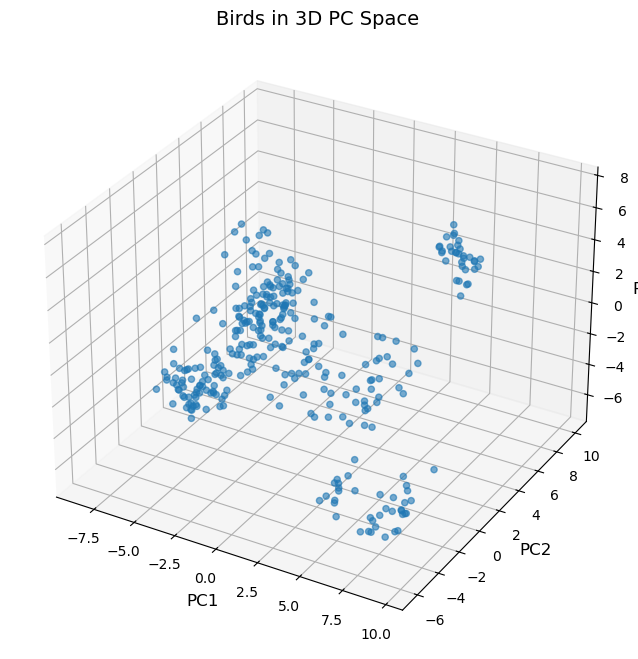

In [6]:
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(birds_pca[:, 0], birds_pca[:, 1], birds_pca[:, 2], alpha=0.6)
ax.set_xlabel('PC1', fontsize=12)
ax.set_ylabel('PC2', fontsize=12)
ax.set_zlabel('PC3', fontsize=12)
ax.set_title('Birds in 3D PC Space', fontsize=14)

plt.show()

## Setting up StableUnCLIP (using starter code)

In [7]:
tqdm._instances.clear()

In [8]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [9]:
recon_pipe = StableUnCLIPImg2ImgPipeline.from_pretrained(
    "sd2-community/stable-diffusion-2-1-unclip", torch_dtype=torch.float32
)

Loading pipeline components...:   0%|          | 0/9 [00:00<?, ?it/s]

In [10]:
recon_pipe = recon_pipe.to("cuda")

In [11]:
def reconstruct_image_from_embedding(recon_pipe, embedding):
    emb_tensor = torch.from_numpy(embedding).unsqueeze(0).to(
        device=recon_pipe.device, 
        dtype=recon_pipe.image_encoder.dtype
    )
    return recon_pipe(image_embeds=emb_tensor).images[0]

## Starting perturbation and reconstruction

In [14]:
random_idx = np.random.choice(len(birds_emb))
original_emb = birds_emb[random_idx]

print(f"Selected image at index: {random_idx}")
print(f"Embedding shape: {original_emb.shape}") 

Selected image at index: 109
Embedding shape: (1024,)


In [15]:
def get_all_images_pathlib(root_folder):
    root_path = Path(root_folder)
    images = []
    
    for file_path in root_path.rglob('*'):
        if file_path.suffix.lower() == '.jpg':
            images.append(str(file_path))
    
    return images

In [16]:
birds_folder = f'{base_dir}COGS118B_FinalProject/Birds'
birds = get_all_images_pathlib(birds_folder)

original_img = birds[random_idx]
print(original_img)

/home/nbohra/COGS118B_FinalProject/Birds/vulture/vulture_07s.jpg


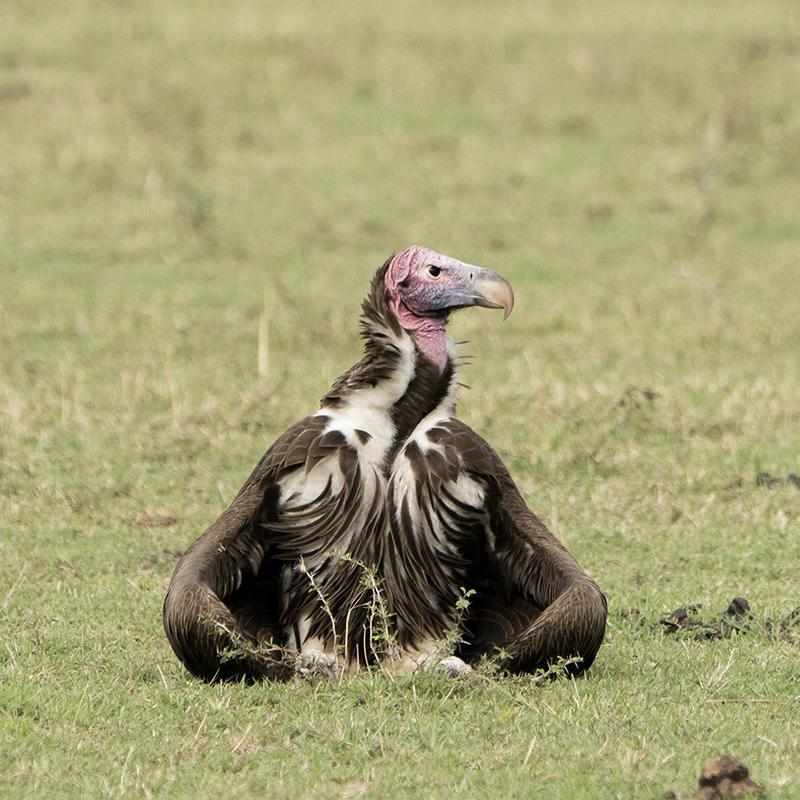

In [17]:
image_path = birds[random_idx]
img = Image.open(image_path)
display(img)

Now, we perturb this embedding in the direction of each of the three top PCs. This is done by scaling and adding the principal component vector to the original CLIP embedding and reconstructing it. We experiment with different $\alpha$ values to see the scale of change along these axes. 

## Perturbation along PC1

In [18]:
pc1_direction = pca_birds.components_[0]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

...

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

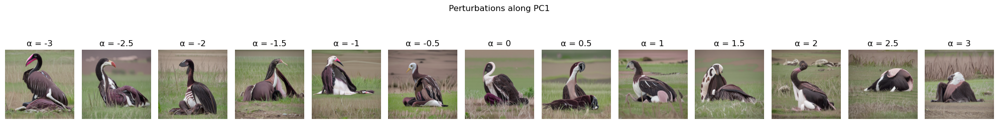

In [19]:
alphas = [-3, -2.5, -2, -1.5, -1, -0.5, 0, 0.5, 1, 1.5, 2, 2.5, 3]
fig, axes = plt.subplots(1, len(alphas), figsize=(20, 3))

for i, alpha in enumerate(alphas):
    perturbed_emb = original_emb + alpha * pc1_direction
    reconstructed = reconstruct_image_from_embedding(recon_pipe, perturbed_emb)
    
    axes[i].imshow(reconstructed)
    axes[i].set_title(f'α = {alpha}')
    axes[i].axis('off')

plt.suptitle('Perturbations along PC1')
plt.tight_layout()
plt.show()

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

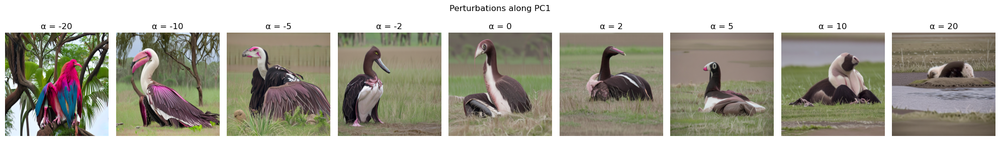

In [20]:
alphas = [-20, -10, -5, -2, 0, 2, 5, 10, 20]
fig, axes = plt.subplots(1, len(alphas), figsize=(20, 3))

for i, alpha in enumerate(alphas):
    perturbed_emb = original_emb + alpha * pc1_direction
    reconstructed = reconstruct_image_from_embedding(recon_pipe, perturbed_emb)
    
    axes[i].imshow(reconstructed)
    axes[i].set_title(f'α = {alpha}')
    axes[i].axis('off')

plt.suptitle('Perturbations along PC1')
plt.tight_layout()
plt.show()

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

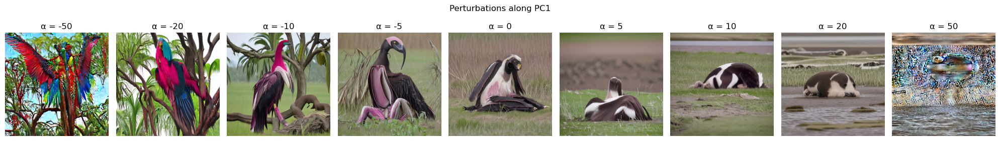

In [21]:
alphas = [-50, -20, -10, -5, 0, 5, 10, 20, 50]
fig, axes = plt.subplots(1, len(alphas), figsize=(20, 3))

for i, alpha in enumerate(alphas):
    perturbed_emb = original_emb + alpha * pc1_direction
    reconstructed = reconstruct_image_from_embedding(recon_pipe, perturbed_emb)
    
    axes[i].imshow(reconstructed)
    axes[i].set_title(f'α = {alpha}')
    axes[i].axis('off')

plt.suptitle('Perturbations along PC1')
plt.tight_layout()
plt.show()

## Perturbation along PC2

In [22]:
pc2_direction = pca_birds.components_[1]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

...

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

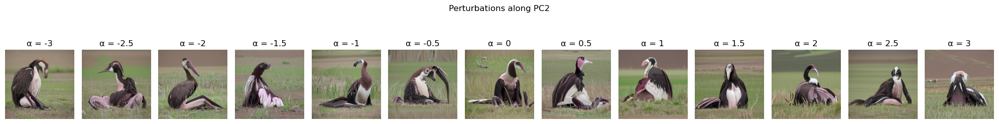

In [23]:
alphas = [-3, -2.5, -2, -1.5, -1, -0.5, 0, 0.5, 1, 1.5, 2, 2.5, 3]
fig, axes = plt.subplots(1, len(alphas), figsize=(20, 3))

for i, alpha in enumerate(alphas):
    perturbed_emb = original_emb + alpha * pc2_direction
    reconstructed = reconstruct_image_from_embedding(recon_pipe, perturbed_emb)
    
    axes[i].imshow(reconstructed)
    axes[i].set_title(f'α = {alpha}')
    axes[i].axis('off')

plt.suptitle('Perturbations along PC2')
plt.tight_layout()
plt.show()

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

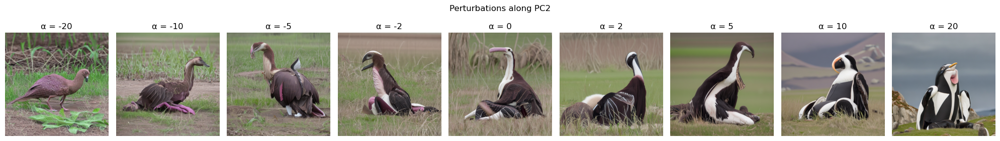

In [24]:
alphas = [-20, -10, -5, -2, 0, 2, 5, 10, 20]
fig, axes = plt.subplots(1, len(alphas), figsize=(20, 3))

for i, alpha in enumerate(alphas):
    perturbed_emb = original_emb + alpha * pc2_direction
    reconstructed = reconstruct_image_from_embedding(recon_pipe, perturbed_emb)
    
    axes[i].imshow(reconstructed)
    axes[i].set_title(f'α = {alpha}')
    axes[i].axis('off')

plt.suptitle('Perturbations along PC2')
plt.tight_layout()
plt.show()

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

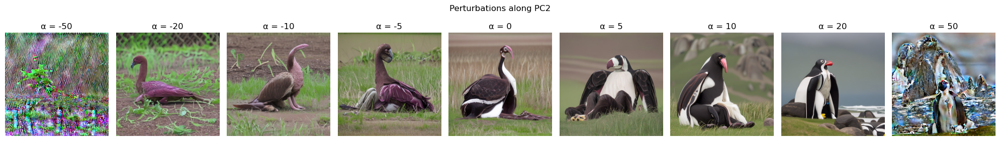

In [25]:
alphas = [-50, -20, -10, -5, 0, 5, 10, 20, 50]
fig, axes = plt.subplots(1, len(alphas), figsize=(20, 3))

for i, alpha in enumerate(alphas):
    perturbed_emb = original_emb + alpha * pc2_direction
    reconstructed = reconstruct_image_from_embedding(recon_pipe, perturbed_emb)
    
    axes[i].imshow(reconstructed)
    axes[i].set_title(f'α = {alpha}')
    axes[i].axis('off')

plt.suptitle('Perturbations along PC2')
plt.tight_layout()
plt.show()

## Perturbation along PC3

In [26]:
pc3_direction = pca_birds.components_[2]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

...

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

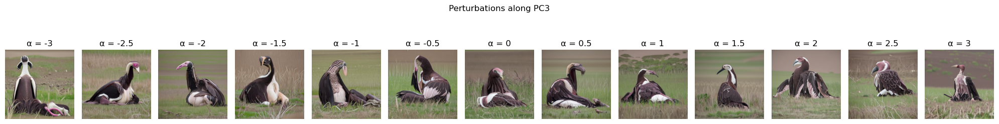

In [27]:
alphas = [-3, -2.5, -2, -1.5, -1, -0.5, 0, 0.5, 1, 1.5, 2, 2.5, 3]
fig, axes = plt.subplots(1, len(alphas), figsize=(20, 3))

for i, alpha in enumerate(alphas):
    perturbed_emb = original_emb + alpha * pc3_direction
    reconstructed = reconstruct_image_from_embedding(recon_pipe, perturbed_emb)
    
    axes[i].imshow(reconstructed)
    axes[i].set_title(f'α = {alpha}')
    axes[i].axis('off')

plt.suptitle('Perturbations along PC3')
plt.tight_layout()
plt.show()

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

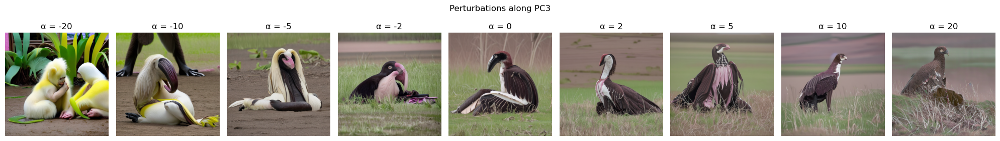

In [28]:
alphas = [-20, -10, -5, -2, 0, 2, 5, 10, 20]
fig, axes = plt.subplots(1, len(alphas), figsize=(20, 3))

for i, alpha in enumerate(alphas):
    perturbed_emb = original_emb + alpha * pc3_direction
    reconstructed = reconstruct_image_from_embedding(recon_pipe, perturbed_emb)
    
    axes[i].imshow(reconstructed)
    axes[i].set_title(f'α = {alpha}')
    axes[i].axis('off')

plt.suptitle('Perturbations along PC3')
plt.tight_layout()
plt.show()

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

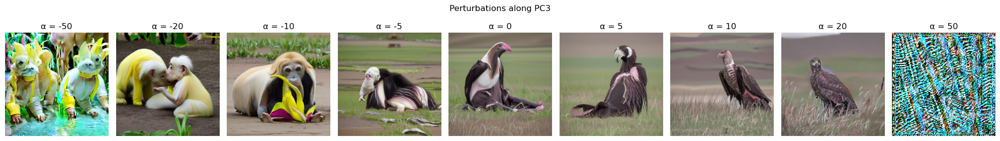

In [29]:
alphas = [-50, -20, -10, -5, 0, 5, 10, 20, 50]
fig, axes = plt.subplots(1, len(alphas), figsize=(20, 3))

for i, alpha in enumerate(alphas):
    perturbed_emb = original_emb + alpha * pc3_direction
    reconstructed = reconstruct_image_from_embedding(recon_pipe, perturbed_emb)
    
    axes[i].imshow(reconstructed)
    axes[i].set_title(f'α = {alpha}')
    axes[i].axis('off')

plt.suptitle('Perturbations along PC3')
plt.tight_layout()
plt.show()

## Visualizing Perturbations at a High-level

In [30]:
# Here we select 5 images randomly and show the results of perturbations using the first 3 PCs over a set of alpha values. 

In [33]:
n_images = 5  # number of different images to analyze
pcs_indices = [0, 1, 2]

# set 
alphas = [-50, -40, -30, -20, -10, -5, -2, -1, 0, 1, 2, 5, 10, 20, 30, 40, 50]

In [34]:
# Randomly selecting imgs for perturbation+reconstruction
random_indices = np.random.choice(len(birds_emb), size=n_images, replace=False)

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

...

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

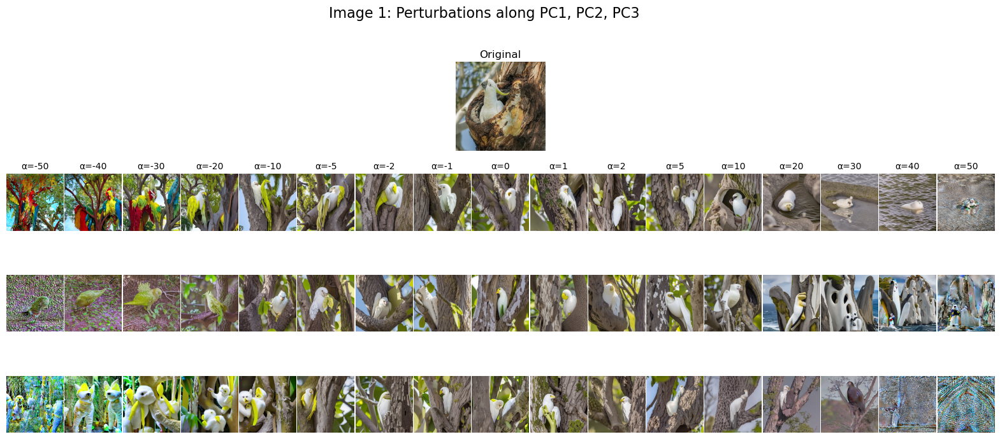

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

...

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

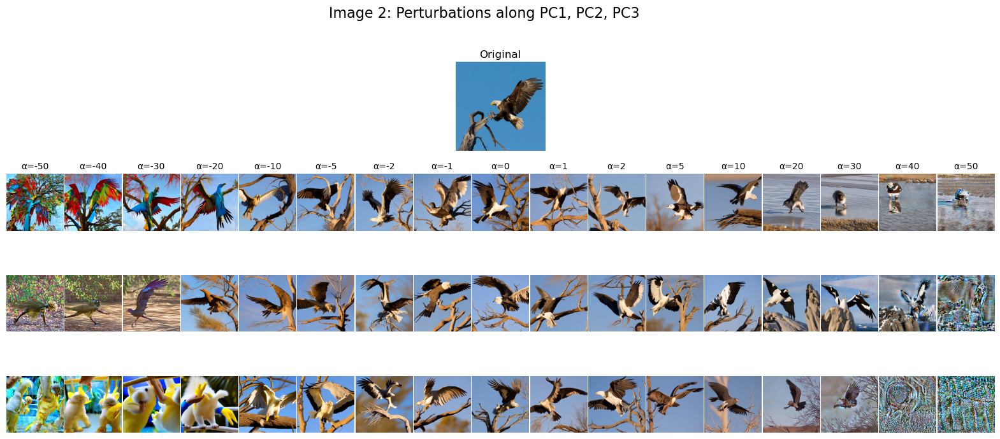

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

...

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

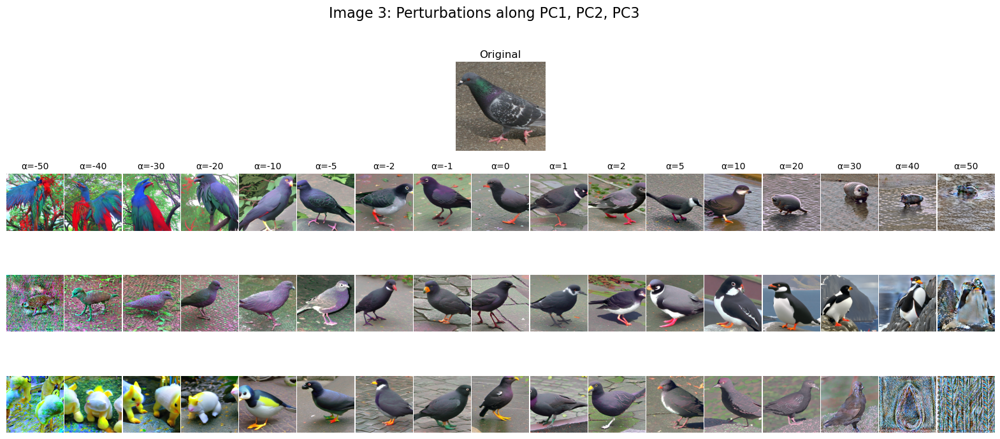

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

...

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

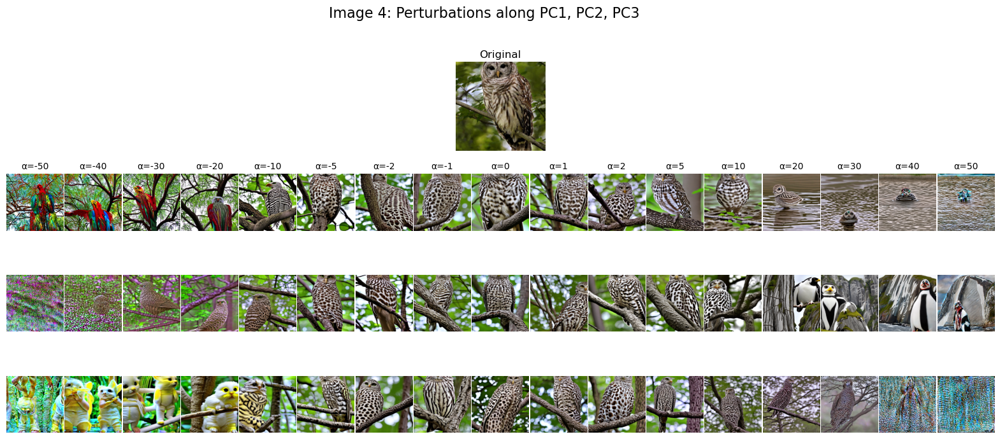

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

...

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

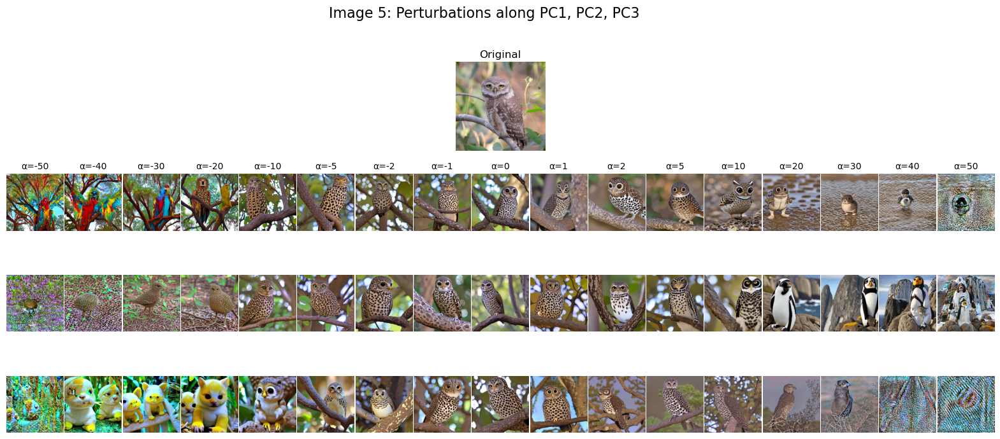

In [36]:
for img_num, idx in enumerate(random_indices):
    original_emb = birds_emb[idx]
    original_img = Image.open(birds[idx])
    
    fig = plt.figure(figsize=(20, 8))
    
    gs = gridspec.GridSpec(len(pcs_indices) + 1, len(alphas), 
                          height_ratios=[0.9] + [1]*len(pcs_indices),
                          hspace=0.02, wspace=0.02)
    
    ax_orig = fig.add_subplot(gs[0, len(alphas)//2 - 1:len(alphas)//2 + 2])
    ax_orig.imshow(original_img)
    ax_orig.axis('off')
    ax_orig.set_title('Original', fontsize=12, pad=5)
    
    # Creating perturbation grid
    for row, pc_idx in enumerate(pcs_indices):
        pc_direction = pca_birds.components_[pc_idx]
        
        for col, alpha in enumerate(alphas):
            # Perturbing embs
            perturbed_emb = original_emb + alpha * pc_direction
            
            # Reconstructing perturbs imgs
            reconstructed = reconstruct_image_from_embedding(recon_pipe, perturbed_emb)
            
            ax = fig.add_subplot(gs[row + 1, col])
            ax.imshow(reconstructed)
            ax.axis('off')

            if col == 0:
                ax.set_ylabel(f'PC{pc_idx+1}', fontsize=14, rotation=0, labelpad=30)
            if row == 0:
                ax.set_title(f'α={alpha}', fontsize=10)
    
    plt.suptitle(f'Image {img_num+1}: Perturbations along PC1, PC2, PC3', 
                 fontsize=16, y=0.99)
    plt.show()

## Creating and comparing synthetic images at the ends of the PCs

Now, we generate a prototypical bird using the mean CLIP embedding and pull it along the different PC axes to visualize what the prototypical change along these axes may be in an effort to discover what image features they encode.

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

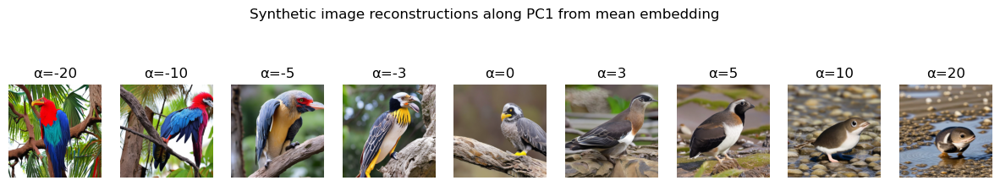

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

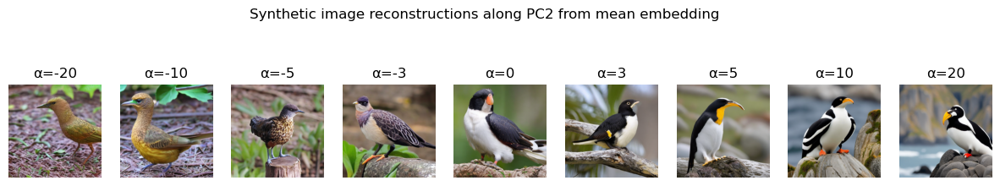

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

  0%|          | 0/21 [00:00<?, ?it/s]

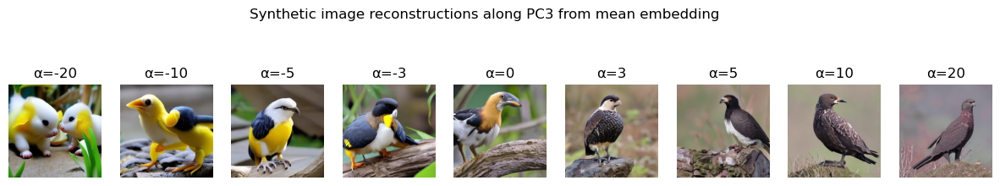

In [12]:
# Taking mean CLIP embedding of all animals
mean_emb = birds_emb.mean(axis=0)

for pc_idx in range(3):
    pc_direction = pca_birds.components_[pc_idx]
    
    # Creating pts in space (sliding along PC axis)
    extreme_values = [-20,-10, -5, -3, 0,3, 5,10,20]
    fig, axes = plt.subplots(1, len(extreme_values), figsize=(15, 3))
    
    for i, alpha in enumerate(extreme_values):
        # Pulling mean emb to extremes of top3 PC axes
        synthetic_emb = mean_emb + alpha * pc_direction
        reconstructed = reconstruct_image_from_embedding(recon_pipe, synthetic_emb)
        
        axes[i].imshow(reconstructed)
        axes[i].set_title(f'α={alpha}')
        axes[i].axis('off')
    
    plt.suptitle(f'Synthetic image reconstructions along PC{pc_idx+1} from mean embedding')
    plt.show()